# The Thiem model for confined, steady flow in semi-infinite aquifers

In [1]:
# GEOSCI-627 Class 14

#Import needed modules
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt

from scipy.integrate import quad

# The Thiem Solution

The Thiem solution (pronounced "team solution") represents the steady drawdown expected at a distance r from a pumping well. Since it is a steady solution, in this case we do not need to worry about generating plots as a function of time.

Recall, assumptions of the Theim solution include:
- A fully saturated aquifer, confined with constant transmissivity (T)
- (to determine the integration constant), a location at which the head does not change, the so-called "radius of influence"


In [2]:
#Define the Thiem solution - representing hydraulic head
#This version of the solution automatically solves for the integration constant
#such that head at r0 is equal to h0
def Thiem_sol(Q, T, r, h0, r0):
    h = Q/(2*np.pi*T)*(np.log(r) - np.log(r0)) + h0
    return h


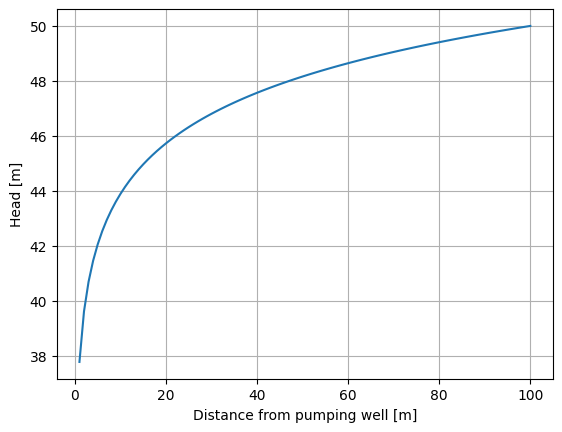

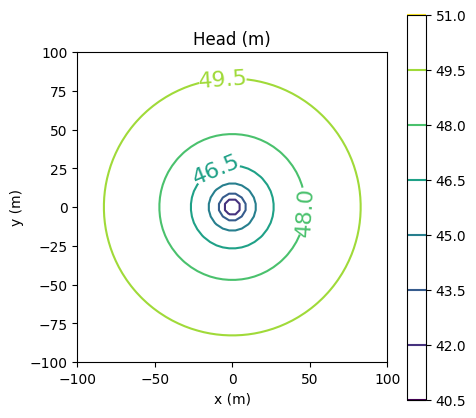

In [3]:
#Plot an example of "field data" that would be measured if the Thiem solution
#(steady, confined flow) applies
Q = 25 # m^3/day
K = 0.05 # m/day
b = 30 # m
T = K*b

h0 = 50 # m
r0 = 100 # m 

r = np.linspace(1,100,100)
head_1d = Thiem_sol(Q,T,r,h0,r0)

#1-D plot as a function of radius
fig, ax = plt.subplots()
ax.plot(r,head_1d)
ax.grid(visible='yes')
ax.set_xlabel('Distance from pumping well [m]')
ax.set_ylabel('Head [m]')

#2-D plot as a function of x, y
x_coords = np.linspace(-100,100,50)
y_coords = np.linspace(-100,100,50)
xc,yc = np.meshgrid(x_coords,y_coords)
head_2d = Q/(2*np.pi*T)*(np.log(((xc)**2 + (yc)**2)**(1/2)) - np.log(r0)) + h0
fig, ax = plt.subplots(figsize=(5, 5))
cp = ax.contour(xc, yc, head_2d)
#Modify the contour plot by labeling the contours
ax.clabel(cp, cp.levels, inline=True, fontsize=16)
ax.set_aspect('equal','box')
ax.set_xlabel('x (m)')
ax.set_ylabel('y (m)')
ax.set_title('Head (m)')
fig.colorbar(cp)
plt.show()


## Questions to Consider

1. Does positive Q correspond to a pumping rate or an injection rate, for this solution?
2. Suppose you're using the Thiem equation to simulate pumping from the center of  an island that matches the descriptions above, i.e. head = 50 along the island's radius of r = 100 m, and the island's aquifer is confined, homogeneous, and 30m thick. Will the solution be realistic no matter the pumping rate?


## Using the Thiem Solution to interpret pump test data

Now, we will use the "synthetic" data generated above for an aquifer to plot drawdown vs. log-radius. Using the result from class, we will evaluate the change in drawdown per log-radius and use this to estimate T



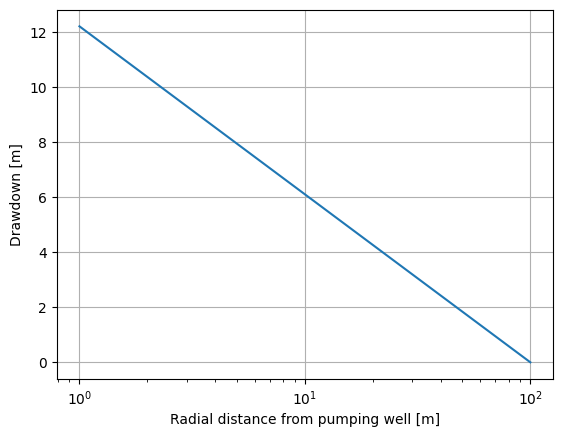

In [4]:
#Generate drawdown data from the synthetic data
s_thiem = h0 - head_1d
fig, ax = plt.subplots()

ax.plot(r,s_thiem)
ax.grid(visible='yes')
ax.set_xscale('log')
ax.set_xlabel('Radial distance from pumping well [m]')
ax.set_ylabel('Drawdown [m]')
plt.show()

## Questions to Try

1. What do you obtain for "drawdown per log-radius" from the data above?
2. Based on this result, what estimate of aquifer transmissivity do you get? Is it comparable to the "true" value (i.e., the value through which we generated the data)?


In [5]:
#Use the Thiem solution to estimate the aquifer transmissivity

# EDIT: Enter the drawdown change per log-cycle of radius
deltas_perlog10r = 2
T_estimate = 2.3*Q/(2*np.pi)*1/deltas_perlog10r
print('Using the Thiem "drawdown vs. log-radius" approach, we estimate T = ', T_estimate)

Using the Thiem "drawdown vs. log-radius" approach, we estimate T =  4.575704613891991
